# Analisis Sentimen Review Sunscreen (Negatif vs Positif)

Alur notebook:

1. Data: hanya kelas **negatif** dan **positif** (netral dibuang), lalu EDA dan preprocessing
2. Split train / validation / test (stratified)
3. Baseline: TF-IDF + Logistic Regression, Word2Vec + Logistic Regression
4. Peningkatan:
   - TF-IDF (word + char n-gram) + **LightGBM**
   - **Back-translation** (augmentasi kelas negatif, hanya pada data latih)
   - Fine-tuning **mDeBERTa-v3** dengan **weighted cross-entropy / focal loss**
   - Ensemble
5. Perbandingan akhir dan analisis kesalahan

> Bagian 8 dan 9 membutuhkan GPU (Colab: Runtime > Change runtime type > T4 GPU).
> Karena kelas sangat timpang (negatif kurang dari 15%), metrik utama adalah **macro-F1** dan **F1 kelas negatif**, bukan akurasi.

## 0. Setup

In [1]:
!pip install -q transformers accelerate sentencepiece sacremoses lightgbm gensim

In [2]:
import os, re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from scipy.sparse import hstack

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

warnings.filterwarnings("ignore")
nltk.download("stopwords", quiet=True)
sns.set_theme(style="whitegrid")

DATA_PATH = "/content/sociola.csv"
SEED = 42
LABELS = ["negatif", "positif"]      # 0 = negatif, 1 = positif


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


set_seed(SEED)

## 1. Data

Kelas **netral dibuang** sejak awal, sehingga seluruh eksperimen memakai 2 kelas.
Alasannya (dari eksperimen sebelumnya): pada 3 kelas, model hampir tidak pernah memprediksi netral dan banyak review positif ikut terlempar ke negatif.

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Ukuran data awal:", raw.shape)
print(raw["sentiment"].value_counts().to_string())

df = raw[raw["sentiment"].isin(["negative", "positive"])].copy()
df["label"] = (df["sentiment"] == "positive").astype(int)        # 0 = negatif, 1 = positif
df["label_name"] = df["label"].map(dict(enumerate(LABELS)))
df = df.reset_index(drop=True)

print(f"\nSetelah netral dibuang: {df.shape}")
print(df["label_name"].value_counts().to_string())
print(f"Rasio negatif: {(df['label'] == 0).mean():.1%}")

Ukuran data awal: (1906, 4)
sentiment
positive    1581
negative     236
neutral       89

Setelah netral dibuang: (1817, 6)
label_name
positif    1581
negatif     236
Rasio negatif: 13.0%


## 2. Preprocessing dan EDA

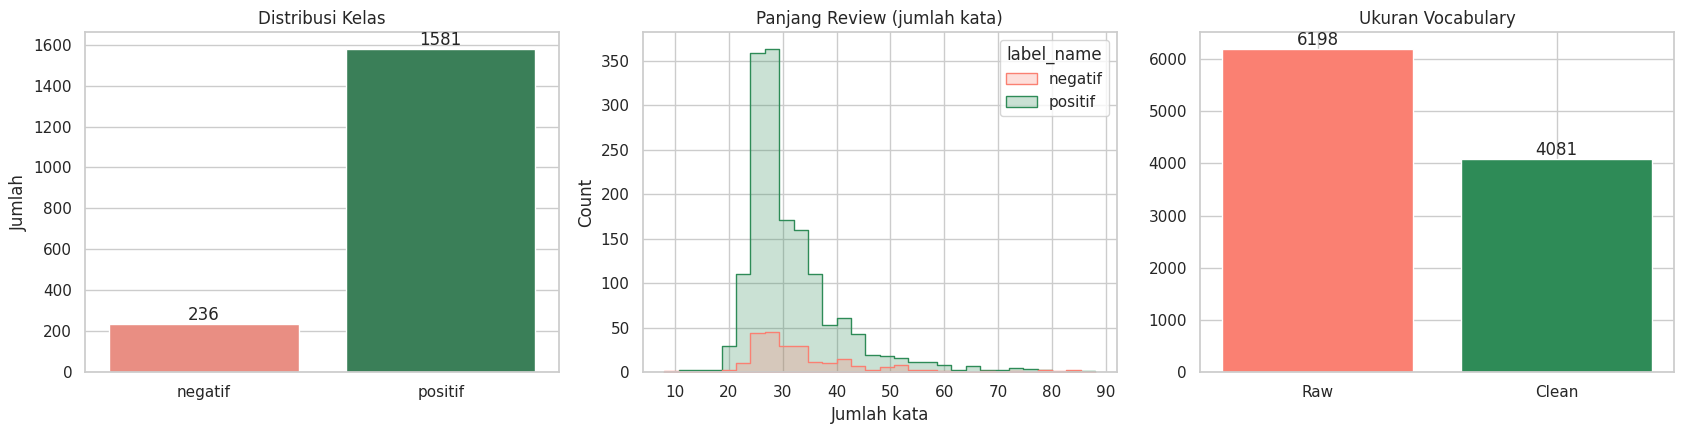

            raw_words  clean_words
label_name                        
negatif          34.1         34.2
positif          31.4         31.4


,review,clean_text,label_name
546,sunscreen ini awalnya ke beli karena bisa di g...,sunscreen ini awalnya ke beli karena bisa di g...,positif
1005,gampang banget dipakai enggak perlu hapus make...,gampang banget dipakai enggak perlu hapus make...,negatif
1767,"al day light sunscreen spray, demi apa ya saya...",al day light sunscreen spray demi apa ya sayan...,positif
840,bagus banget aku suka tapi cepat banget abisny...,bagus banget aku suka tapi cepat banget abisny...,negatif


In [4]:
keep_words = {"tidak", "tak", "bukan", "belum", "kurang", "jangan", "tanpa",
              "tapi", "tetapi", "namun", "sangat", "sekali", "cukup", "lebih", "masih"}
# hanya kata tunggal (stopword bertanda hubung seperti "berkali-kali" memicu warning di TfidfVectorizer)
stop_words_id = {w for w in stopwords.words("indonesian") if re.fullmatch(r"\w+", w)} - keep_words
STOP_LIST = sorted(stop_words_id)


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"(.)\1{2,}", r"\1", text)          # "bagusssss" -> "bagus"
    text = re.sub(r"[^a-z\s]", " ", text)              # buang angka, tanda baca, emoji
    return re.sub(r"\s+", " ", text).strip()


df["clean_text"] = df["review"].map(clean_text)
df["raw_words"] = df["review"].str.split().str.len()
df["clean_words"] = df["clean_text"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(data=df, x="label_name", order=LABELS, ax=axes[0], palette=["salmon", "seagreen"])
axes[0].set_title("Distribusi Kelas"); axes[0].set_xlabel(""); axes[0].set_ylabel("Jumlah")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

sns.histplot(data=df, x="raw_words", hue="label_name", bins=30, hue_order=LABELS,
             palette=["salmon", "seagreen"], ax=axes[1], element="step")
axes[1].set_title("Panjang Review (jumlah kata)"); axes[1].set_xlabel("Jumlah kata")

raw_vocab = len(set(" ".join(df["review"].str.lower()).split()))
clean_vocab = len(set(" ".join(df["clean_text"]).split()))
axes[2].bar(["Raw", "Clean"], [raw_vocab, clean_vocab], color=["salmon", "seagreen"])
axes[2].set_title("Ukuran Vocabulary")
for i, v in enumerate([raw_vocab, clean_vocab]):
    axes[2].text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

print(df.groupby("label_name")[["raw_words", "clean_words"]].mean().round(1))
display(df[["review", "clean_text", "label_name"]].sample(4, random_state=1))

## 3. Split data

Split stratified: **70% train / 12% validation / 18% test** (kira-kira).
Validation dipakai untuk early stopping dan menentukan *threshold* keputusan; **test hanya dipakai sekali untuk evaluasi akhir**.
Semua model memakai split yang sama agar bisa dibandingkan langsung.

In [5]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.15, stratify=train_df["label"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):5d} baris | negatif={int((d['label']==0).sum()):4d} | positif={int((d['label']==1).sum()):4d}")

train:  1235 baris | negatif= 161 | positif=1074
val  :   218 baris | negatif=  28 | positif= 190
test :   364 baris | negatif=  47 | positif= 317


## 4. Fungsi evaluasi

Semua model menghasilkan **P(negatif)** untuk data validation dan test. Review diprediksi negatif jika `P(negatif) >= threshold`.
Dua skenario dilaporkan: threshold default 0.5, dan threshold yang **dituning di validation** untuk memaksimalkan macro-F1.
Ini penting karena kelas negatif jarang, sehingga threshold 0.5 hampir selalu terlalu konservatif.

In [6]:
preds = {}     # nama model -> {"val": P(neg) val, "test": P(neg) test, "runs": [(val, test), ...] jika multi-seed}


def tune_threshold(y_true, p_neg):
    grid = np.linspace(0.05, 0.95, 91)
    scores = [f1_score(y_true, np.where(p_neg >= t, 0, 1), average="macro") for t in grid]
    return float(grid[int(np.argmax(scores))])


def metrics(y_true, p_neg, thr):
    pred = np.where(p_neg >= thr, 0, 1)
    return {"macro_f1": f1_score(y_true, pred, average="macro"),
            "f1_negatif": f1_score(y_true, pred, pos_label=0),
            "f1_positif": f1_score(y_true, pred, pos_label=1),
            "accuracy": accuracy_score(y_true, pred)}


def register(name, p_val, p_test, runs=None):
    preds[name] = {"val": np.asarray(p_val), "test": np.asarray(p_test), "runs": runs}
    m_def = metrics(y_test, preds[name]["test"], 0.5)
    thr = tune_threshold(y_val, preds[name]["val"])
    m_tun = metrics(y_test, preds[name]["test"], thr)
    print(f"{name}\n   thr=0.50  macro-F1={m_def['macro_f1']:.3f}  F1-neg={m_def['f1_negatif']:.3f}  acc={m_def['accuracy']:.3f}"
          f"\n   thr={thr:.2f}  macro-F1={m_tun['macro_f1']:.3f}  F1-neg={m_tun['f1_negatif']:.3f}  acc={m_tun['accuracy']:.3f}")


def val_score(name):
    d = preds[name]
    runs = d["runs"] or [(d["val"], d["test"])]
    return np.mean([metrics(y_val, pv, tune_threshold(y_val, pv))["macro_f1"] for pv, _ in runs])


def summarize():
    rows = []
    for name, d in preds.items():
        runs = d["runs"] or [(d["val"], d["test"])]
        for mode in ["thr=0.5", "tuned"]:
            ms = [metrics(y_test, pt, 0.5 if mode == "thr=0.5" else tune_threshold(y_val, pv)) for pv, pt in runs]
            m = pd.DataFrame(ms)
            rows.append({"model": name, "threshold": mode, **m.mean().to_dict(),
                         "macro_f1_std": m["macro_f1"].std(ddof=0) if len(ms) > 1 else np.nan,
                         "val_macro_f1": val_score(name)})
    return pd.DataFrame(rows)

## 5. Baseline

**TF-IDF + Logistic Regression** (`class_weight="balanced"`) dan **Word2Vec + Logistic Regression**, sama seperti eksperimen sebelumnya tetapi dievaluasi pada split baru.

In [7]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words=STOP_LIST)
Xtr = tfidf.fit_transform(train_df["clean_text"])
Xva, Xte = tfidf.transform(val_df["clean_text"]), tfidf.transform(test_df["clean_text"])

lr = LogisticRegression(max_iter=1000, solver="liblinear", class_weight="balanced", random_state=SEED).fit(Xtr, y_train)
register("Baseline: TF-IDF + LogReg", lr.predict_proba(Xva)[:, 0], lr.predict_proba(Xte)[:, 0])

Baseline: TF-IDF + LogReg
   thr=0.50  macro-F1=0.667  F1-neg=0.421  acc=0.849
   thr=0.54  macro-F1=0.667  F1-neg=0.410  acc=0.865


In [8]:
from gensim.models import Word2Vec


def tokenize(text):
    return [w for w in text.split() if w not in stop_words_id]


def avg_vectors(kv, token_lists, dim):
    out = np.zeros((len(token_lists), dim), dtype=np.float32)
    for i, toks in enumerate(token_lists):
        vecs = [kv[w] for w in toks if w in kv]
        if vecs:
            out[i] = np.mean(vecs, axis=0)
    return out


tok_tr, tok_va, tok_te = [[tokenize(t) for t in d["clean_text"]] for d in (train_df, val_df, test_df)]
w2v = Word2Vec(tok_tr, vector_size=100, window=5, min_count=2, sg=1, epochs=50, seed=SEED, workers=1)  # hanya data latih
E_tr, E_va, E_te = [avg_vectors(w2v.wv, t, 100) for t in (tok_tr, tok_va, tok_te)]

scaler = StandardScaler().fit(E_tr)
lr_w2v = LogisticRegression(max_iter=3000, C=0.1, class_weight="balanced", random_state=SEED).fit(scaler.transform(E_tr), y_train)
register("Baseline: Word2Vec + LogReg",
         lr_w2v.predict_proba(scaler.transform(E_va))[:, 0], lr_w2v.predict_proba(scaler.transform(E_te))[:, 0])

Baseline: Word2Vec + LogReg
   thr=0.50  macro-F1=0.651  F1-neg=0.417  acc=0.808
   thr=0.80  macro-F1=0.620  F1-neg=0.308  acc=0.876


## 6. TF-IDF (word + char n-gram) + LightGBM

Dua perubahan dibanding baseline:
- Fitur char n-gram (`char_wb`, 2-5) ikut ditambahkan. Ini membantu untuk teks informal Indonesia yang penuh singkatan, salah ketik, dan campuran bahasa Inggris.
- Classifier LightGBM dengan `class_weight="balanced"` dan early stopping di validation. Logistic Regression pada fitur yang sama disertakan sebagai pembanding.

In [9]:
def make_features(train_text, *other_texts):
    word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=8000, sublinear_tf=True, stop_words=STOP_LIST)
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=20000, sublinear_tf=True)
    X_train = hstack([word.fit_transform(train_text), char.fit_transform(train_text)]).tocsr().astype(np.float32)
    others = [hstack([word.transform(t), char.transform(t)]).tocsr().astype(np.float32) for t in other_texts]
    return X_train, others


def run_logreg(train_frame, suffix=""):
    X_tr, (X_va, X_te) = make_features(train_frame["clean_text"], val_df["clean_text"], test_df["clean_text"])
    m = LogisticRegression(C=5, class_weight="balanced", solver="liblinear", max_iter=2000, random_state=SEED)
    m.fit(X_tr, train_frame["label"].values)
    register(f"TF-IDF word+char + LogReg{suffix}", m.predict_proba(X_va)[:, 0], m.predict_proba(X_te)[:, 0])


def run_lightgbm(train_frame, suffix=""):
    import lightgbm as lgb
    X_tr, (X_va, X_te) = make_features(train_frame["clean_text"], val_df["clean_text"], test_df["clean_text"])
    m = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=15, min_child_samples=10,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.3, reg_lambda=1.0,
                           class_weight="balanced", random_state=SEED, verbose=-1)
    m.fit(X_tr, train_frame["label"].values, eval_set=[(X_va, y_val)], eval_metric="binary_logloss",
          callbacks=[lgb.early_stopping(50, verbose=False)])
    print(f"LightGBM best iteration: {m.best_iteration_}")
    register(f"TF-IDF word+char + LightGBM{suffix}", m.predict_proba(X_va)[:, 0], m.predict_proba(X_te)[:, 0])

In [10]:
run_logreg(train_df)
run_lightgbm(train_df)

TF-IDF word+char + LogReg
   thr=0.50  macro-F1=0.714  F1-neg=0.494  acc=0.882
   thr=0.43  macro-F1=0.699  F1-neg=0.480  acc=0.857
LightGBM best iteration: 109
TF-IDF word+char + LightGBM
   thr=0.50  macro-F1=0.637  F1-neg=0.357  acc=0.852
   thr=0.39  macro-F1=0.658  F1-neg=0.415  acc=0.830


## 7. Augmentasi: back-translation kelas negatif

Kelas negatif hanya sekitar 130 review di data latih. Setiap review negatif diterjemahkan Indonesia -> Inggris -> Indonesia
(MarianMT, `Helsinki-NLP/opus-mt-*`) untuk membuat parafrase baru. Dibuat **2 varian** per review: satu dengan beam search, satu dengan sampling agar lebih beragam.

Aturan penting: **augmentasi hanya dari data latih**. Validation dan test tidak disentuh, sehingga tidak ada kebocoran data.
Hasil disimpan ke CSV agar tidak perlu diulang saat notebook dijalankan ulang.

In [11]:
import torch
from transformers import MarianMTModel, MarianTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
AUG_PATH = "aug_backtranslation.csv"


def translate(texts, model_name, batch_size=16, sample=False):
    tok = MarianTokenizer.from_pretrained(model_name)
    mt = MarianMTModel.from_pretrained(model_name).to(device).eval()
    gen_kwargs = dict(do_sample=True, top_p=0.9, temperature=0.8, num_beams=1) if sample else dict(num_beams=4)
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True, truncation=True, max_length=256).to(device)
        with torch.no_grad():
            gen = mt.generate(**enc, max_length=256, **gen_kwargs)
        out += tok.batch_decode(gen, skip_special_tokens=True)
    del mt
    if device == "cuda":
        torch.cuda.empty_cache()
    return out


neg_train = train_df[train_df["label"] == 0]
if os.path.exists(AUG_PATH):
    aug_df = pd.read_csv(AUG_PATH)
    print("Memuat augmentasi dari cache:", AUG_PATH)
else:
    set_seed(SEED)
    src = neg_train["review"].tolist()
    en = translate(src, "Helsinki-NLP/opus-mt-id-en")
    bt_beam = translate(en, "Helsinki-NLP/opus-mt-en-id")
    bt_sample = translate(en, "Helsinki-NLP/opus-mt-en-id", sample=True)
    aug_df = pd.DataFrame({"review": bt_beam + bt_sample, "label": 0})
    aug_df.to_csv(AUG_PATH, index=False)

aug_df["clean_text"] = aug_df["review"].map(clean_text)
aug_df = aug_df[(aug_df["clean_text"].str.split().str.len() >= 3)
                & ~aug_df["clean_text"].isin(set(train_df["clean_text"]))].drop_duplicates("clean_text")

train_aug_df = pd.concat([train_df[["review", "clean_text", "label"]], aug_df[["review", "clean_text", "label"]]],
                         ignore_index=True)
print(f"Review negatif sintetis: {len(aug_df)}")
print(f"Train asli: negatif={int((train_df['label']==0).sum())}, positif={int((train_df['label']==1).sum())}")
print(f"Train + augmentasi: negatif={int((train_aug_df['label']==0).sum())}, positif={int((train_aug_df['label']==1).sum())}")

pd.set_option("display.max_colwidth", 220)
check = pd.DataFrame({"asli": neg_train["review"].head(4).values, "back-translation": aug_df["review"].head(4).values})
display(check)     # periksa manual: makna dan sentimen negatif harus tetap terjaga

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/801k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/796k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.26M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  291MB            

... (15 outputs left out)

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Review negatif sintetis: 318
Train asli: negatif=161, positif=1074
Train + augmentasi: negatif=479, positif=1074


,asli,back-translation
0,sunscreen ini melembapkan tanpa rasa lengket dan cocok dipakai sebagai base makeup. perlindungan uv-nya oke banget! kulit tetap terlindungi dengan baik dan bebas minyak. Ringan tidak lengket dan nyaman untuk penggu...,tabir surya ini dibasahi tanpa rasa lengket dan cocok sebagai basis makeup. perlindungan uv baik-baik saja! kulit terlindungi dengan baik dan bebas minyak. cahaya tidak lengket dan nyaman untuk digunakan setiap hari
1,"teksturnya ringan dan gampang nyerap kulit. glossy finish buat kulit, cuma kayaknya ini cocok buat kulit kering rather tahan oily face. soalnya kulit aku minyakan banget habis beberapa jam. overal bagus",Teksturnya ringan dan mudah menyerap kulit. tapi itu hanya cocok untuk kulit kering dari wajah berminyak yang agak tahan. karena kulit saya begitu diminyaki selama berjam-jam.
2,"menurutku teksturnya lumayan, baunya enak bau aloe vera. sayangnya kurang cocok buat kulit berminyak soalnya spfnya tinggi banget. bikin komedoan dan kulit makin berminyak",aku pikir teksturnya enak baunya seperti aloe vera.
3,"ini sunscreen ok sih. kalo yang punya kulit kering atau kombinasi, mungkin bisa coba ini. sunscreen ini benar-benar ringan, serasa pakai moisturiser dan melembabkan. bagi yang punya kulit kering, ini bisa bikin kulit...","Jika ada yang punya kulit kering atau kombinasi, mungkin coba ini."


In [12]:
# Model klasik dilatih ulang pada data latih + augmentasi (validation dan test tidak berubah)
run_logreg(train_aug_df, " + back-translation")
run_lightgbm(train_aug_df, " + back-translation")

TF-IDF word+char + LogReg + back-translation
   thr=0.50  macro-F1=0.691  F1-neg=0.447  acc=0.885
   thr=0.33  macro-F1=0.691  F1-neg=0.472  acc=0.846
LightGBM best iteration: 135
TF-IDF word+char + LightGBM + back-translation
   thr=0.50  macro-F1=0.638  F1-neg=0.354  acc=0.860
   thr=0.24  macro-F1=0.631  F1-neg=0.403  acc=0.772


## 8. Fine-tuning mDeBERTa-v3 dengan weighted CE / focal loss

**Catatan model:** `deberta-v3-base` dan `roberta-base` dilatih pada teks Inggris, sedangkan review ini berbahasa Indonesia.
Karena itu dipakai **`microsoft/mdeberta-v3-base`**, versi multibahasa dari DeBERTa-v3. Alternatif yang bisa diganti lewat `MODEL_NAME`:
`xlm-roberta-base` atau `indobenchmark/indobert-base-p1` (khusus Indonesia).

Fungsi loss yang dibandingkan:
- **Weighted CE**: bobot kelas `N / (2 * n_kelas)`, sehingga kesalahan pada kelas negatif lebih mahal
- **Focal loss** (gamma=2, alpha = bobot kelas): menurunkan bobot contoh yang sudah mudah (kebanyakan positif) sehingga training fokus pada contoh sulit

Teks input adalah `review` asli (bukan `clean_text`), karena tokenizer transformer sudah menangani tanda baca dan huruf kecil.
Setiap konfigurasi dijalankan dengan beberapa seed karena jumlah review negatif di test kecil, sehingga hasil satu seed bisa berfluktuasi.

In [15]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup

MODEL_NAME = "microsoft/mdeberta-v3-base"
MAX_LEN, BATCH_SIZE, EPOCHS, LR = 128, 16, 5, 2e-5
SEEDS = [42, 43, 44]            # kecilkan menjadi [42] untuk run cepat
use_amp = device == "cuda"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tokenizer)


class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item


class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        logpt = F.log_softmax(logits, dim=-1).gather(1, targets.unsqueeze(1)).squeeze(1)
        loss = -((1 - logpt.exp()) ** self.gamma) * logpt
        if self.alpha is not None:
            loss = loss * self.alpha.to(logits.device)[targets]
        return loss.mean()


def make_criterion(loss_name, labels):
    counts = np.bincount(labels, minlength=2)
    cw = torch.tensor(len(labels) / (2 * counts), dtype=torch.float)
    if loss_name == "wce":
        return nn.CrossEntropyLoss(weight=cw.to(device))
    if loss_name == "focal":
        return FocalLoss(alpha=cw, gamma=2.0)
    return nn.CrossEntropyLoss()


@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    out = []
    for b in loader:
        b = {k: v.to(device) for k, v in b.items() if k != "labels"}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(**b).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.vstack(out)


val_loader = DataLoader(TextDataset(val_df["review"], y_val), batch_size=64, collate_fn=collator)
test_loader = DataLoader(TextDataset(test_df["review"], y_test), batch_size=64, collate_fn=collator)


def train_transformer(train_frame, loss_name, seed):
    set_seed(seed)
    labels = train_frame["label"].values
    loader = DataLoader(TextDataset(train_frame["review"], labels), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).float().to(device)
    criterion = make_criterion(loss_name, labels)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total_steps = EPOCHS * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_f1, best_val, best_test = -1, None, None
    for epoch in range(EPOCHS):
        model.train()
        for b in loader:
            b = {k: v.to(device) for k, v in b.items()}
            y = b.pop("labels")
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(**b).logits
            loss = criterion(logits.float(), y)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()

        p_val = predict_proba(model, val_loader)[:, 0]
        f1 = metrics(y_val, p_val, tune_threshold(y_val, p_val))["macro_f1"]      # pemilihan epoch memakai validation saja
        print(f"   seed={seed} epoch={epoch + 1} loss={loss.item():.3f} val macro-F1 (tuned)={f1:.3f}")
        if f1 > best_f1:
            best_f1, best_val, best_test = f1, p_val, predict_proba(model, test_loader)[:, 0]

    del model, optimizer
    torch.cuda.empty_cache()
    return best_val, best_test

Notebook ini menggunakan 3 seed, 42, 43, dan 44. Melihat 44 dan kemudian 42 lagi berarti satu konfigurasi telah selesai dan konfigurasi berikutnya telah dimulai. Setiap konfigurasi melatih ketiga seed secara berurutan, dan kemudian loop berlanjut ke konfigurasi berikutnya.

Urutannya adalah:

- mDeBERTa + CE berbobot (seed 42, 43, 44)
- mDeBERTa + focal loss (seed 42, 43, 44)
- mDeBERTa + CE berbobot + back-translation (seed 42, 43, 44)
- mDeBERTa + focal loss + back-translation (seed 42, 43, 44)

In [16]:
EXPERIMENTS = {
    "mDeBERTa + weighted CE":                      (train_df,     "wce"),
    "mDeBERTa + focal loss":                       (train_df,     "focal"),
    "mDeBERTa + weighted CE + back-translation":   (train_aug_df, "wce"),
    "mDeBERTa + focal loss + back-translation":    (train_aug_df, "focal"),
}

for name, (frame, loss_name) in EXPERIMENTS.items():
    print(f"\n=== {name} ===")
    runs = [train_transformer(frame, loss_name, s) for s in SEEDS]
    mean_val = np.mean([r[0] for r in runs], axis=0)       # rata-rata probabilitas antar seed
    mean_test = np.mean([r[1] for r in runs], axis=0)
    register(name, mean_val, mean_test, runs=runs)


=== mDeBERTa + weighted CE ===


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.dense.weight              | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
classifier.weight                          | MISSING    | 
pooler.dense.weight 

   seed=42 epoch=1 loss=0.538 val macro-F1 (tuned)=0.805
   seed=42 epoch=2 loss=0.131 val macro-F1 (tuned)=0.864
   seed=42 epoch=3 loss=0.056 val macro-F1 (tuned)=0.860
   seed=42 epoch=4 loss=0.010 val macro-F1 (tuned)=0.860
   seed=42 epoch=5 loss=0.006 val macro-F1 (tuned)=0.860


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.dense.weight              | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
classifier.weight                          | MISSING    | 
pooler.dense.weight 

... (27 outputs left out)

   seed=43 epoch=1 loss=0.007 val macro-F1 (tuned)=0.800
   seed=43 epoch=2 loss=0.005 val macro-F1 (tuned)=0.851
   seed=43 epoch=3 loss=0.002 val macro-F1 (tuned)=0.854
   seed=43 epoch=4 loss=0.000 val macro-F1 (tuned)=0.851
   seed=43 epoch=5 loss=0.000 val macro-F1 (tuned)=0.836


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.dense.weight              | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
classifier.weight                          | MISSING    | 
pooler.dense.weight 

   seed=44 epoch=1 loss=0.002 val macro-F1 (tuned)=0.788
   seed=44 epoch=2 loss=0.211 val macro-F1 (tuned)=0.845
   seed=44 epoch=3 loss=0.001 val macro-F1 (tuned)=0.851
   seed=44 epoch=4 loss=0.001 val macro-F1 (tuned)=0.842
   seed=44 epoch=5 loss=0.000 val macro-F1 (tuned)=0.869
mDeBERTa + focal loss + back-translation
   thr=0.50  macro-F1=0.785  F1-neg=0.617  acc=0.915
   thr=0.24  macro-F1=0.768  F1-neg=0.600  acc=0.890


## 9. Ensemble

Soft voting: rata-rata P(negatif) dari model transformer terbaik dan model klasik terbaik (dipilih berdasarkan skor **validation**, bukan test).
Model berbasis kata/karakter dan model transformer biasanya melakukan kesalahan yang berbeda, sehingga rata-ratanya sering lebih stabil.

In [17]:
transformer_names = [n for n in preds if n.startswith("mDeBERTa")]
classical_names = [n for n in preds if n.startswith("TF-IDF word+char")]
best_tr = max(transformer_names, key=val_score)
best_cl = max(classical_names, key=val_score)
print("Transformer terbaik (val):", best_tr)
print("Klasik terbaik (val)     :", best_cl)

register(f"Ensemble: {best_tr} + {best_cl}",
         (preds[best_tr]["val"] + preds[best_cl]["val"]) / 2,
         (preds[best_tr]["test"] + preds[best_cl]["test"]) / 2)

Transformer terbaik (val): mDeBERTa + focal loss
Klasik terbaik (val)     : TF-IDF word+char + LogReg
Ensemble: mDeBERTa + focal loss + TF-IDF word+char + LogReg
   thr=0.50  macro-F1=0.732  F1-neg=0.529  acc=0.887
   thr=0.51  macro-F1=0.732  F1-neg=0.529  acc=0.887


## 10. Perbandingan akhir

,model,threshold,macro_f1,macro_f1_std,f1_negatif,f1_positif,accuracy,val_macro_f1
0,mDeBERTa + weighted CE + back-translation,tuned,0.766,0.012,0.589,0.943,0.899,0.856
1,mDeBERTa + focal loss + back-translation,tuned,0.764,0.034,0.589,0.938,0.893,0.864
2,mDeBERTa + focal loss,tuned,0.763,0.023,0.588,0.938,0.892,0.872
3,mDeBERTa + weighted CE,tuned,0.759,0.021,0.581,0.936,0.889,0.864
4,Ensemble: mDeBERTa + focal loss + TF-IDF word+char + LogReg,tuned,0.732,NaN,0.529,0.936,0.887,0.878
5,TF-IDF word+char + LogReg,tuned,0.699,NaN,0.480,0.917,0.857,0.825
6,TF-IDF word+char + LogReg + back-translation,tuned,0.691,NaN,0.472,0.910,0.846,0.749
7,Baseline: TF-IDF + LogReg,tuned,0.667,NaN,0.410,0.924,0.865,0.766
8,TF-IDF word+char + LightGBM,tuned,0.658,NaN,0.415,0.900,0.830,0.722
9,TF-IDF word+char + LightGBM + back-translation,tuned,0.631,NaN,0.403,0.859,0.772,0.712


Threshold default 0.5 (untuk perbandingan):


,model,threshold,macro_f1,macro_f1_std,f1_negatif,f1_positif,accuracy,val_macro_f1
0,mDeBERTa + focal loss + back-translation,thr=0.5,0.766,0.012,0.583,0.949,0.908,0.864
1,mDeBERTa + weighted CE,thr=0.5,0.760,0.015,0.588,0.932,0.883,0.864
2,mDeBERTa + focal loss,thr=0.5,0.758,0.021,0.579,0.938,0.892,0.872
3,mDeBERTa + weighted CE + back-translation,thr=0.5,0.736,0.013,0.531,0.941,0.896,0.856
4,Ensemble: mDeBERTa + focal loss + TF-IDF word+char + LogReg,thr=0.5,0.732,NaN,0.529,0.936,0.887,0.878
5,TF-IDF word+char + LogReg,thr=0.5,0.714,NaN,0.494,0.933,0.882,0.825
6,TF-IDF word+char + LogReg + back-translation,thr=0.5,0.691,NaN,0.447,0.936,0.885,0.749
7,Baseline: TF-IDF + LogReg,thr=0.5,0.667,NaN,0.421,0.913,0.849,0.766
8,Baseline: Word2Vec + LogReg,thr=0.5,0.651,NaN,0.417,0.885,0.808,0.697
9,TF-IDF word+char + LightGBM + back-translation,thr=0.5,0.638,NaN,0.354,0.921,0.860,0.712


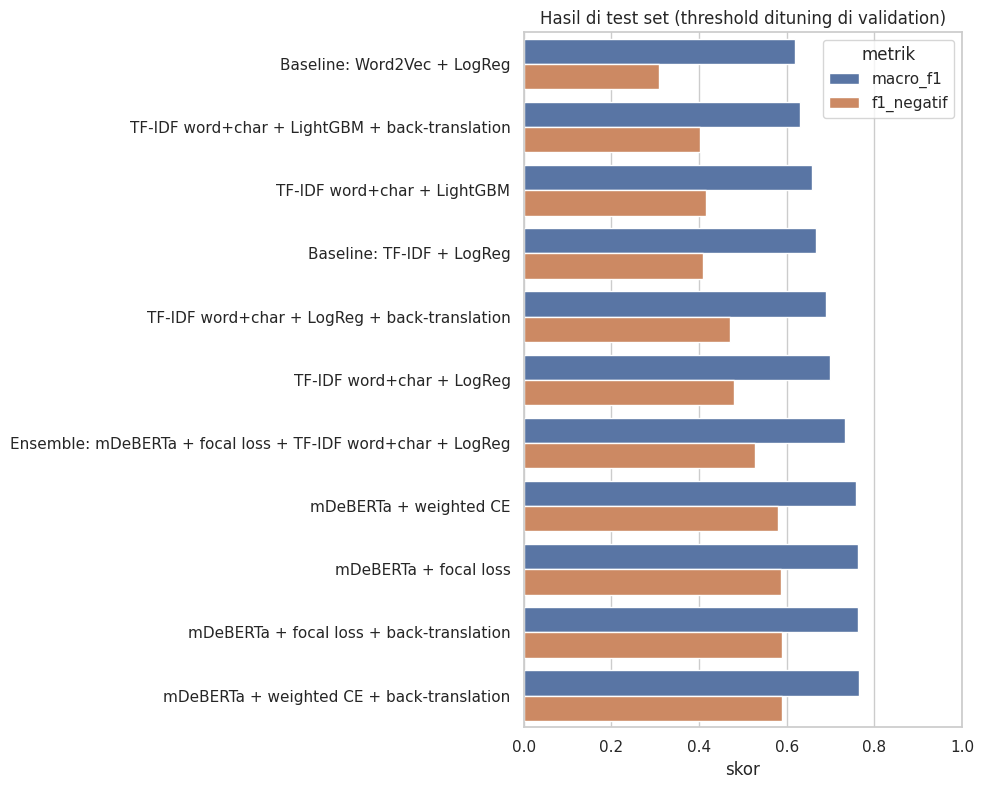

In [18]:
summary = summarize()
cols = ["model", "threshold", "macro_f1", "macro_f1_std", "f1_negatif", "f1_positif", "accuracy", "val_macro_f1"]
display(summary[summary["threshold"] == "tuned"].sort_values("macro_f1", ascending=False)[cols].round(3).reset_index(drop=True))

print("Threshold default 0.5 (untuk perbandingan):")
display(summary[summary["threshold"] == "thr=0.5"].sort_values("macro_f1", ascending=False)[cols].round(3).reset_index(drop=True))

plot_df = (summary[summary["threshold"] == "tuned"]
           .melt(id_vars="model", value_vars=["macro_f1", "f1_negatif"], var_name="metrik", value_name="skor"))
order = summary[summary["threshold"] == "tuned"].sort_values("macro_f1")["model"]
plt.figure(figsize=(10, 0.55 * len(order) + 2))
sns.barplot(data=plot_df, y="model", x="skor", hue="metrik", order=order)
plt.title("Hasil di test set (threshold dituning di validation)"); plt.xlim(0, 1); plt.ylabel("")
plt.tight_layout(); plt.show()

## 11. Analisis kesalahan model terbaik

Model dipilih berdasarkan macro-F1 di **validation**.

Model terbaik (val): Ensemble: mDeBERTa + focal loss + TF-IDF word+char + LogReg | threshold=0.51

              precision    recall  f1-score   support

     negatif      0.575     0.489     0.529        47
     positif      0.926     0.946     0.936       317

    accuracy                          0.887       364
   macro avg      0.750     0.718     0.732       364
weighted avg      0.881     0.887     0.883       364



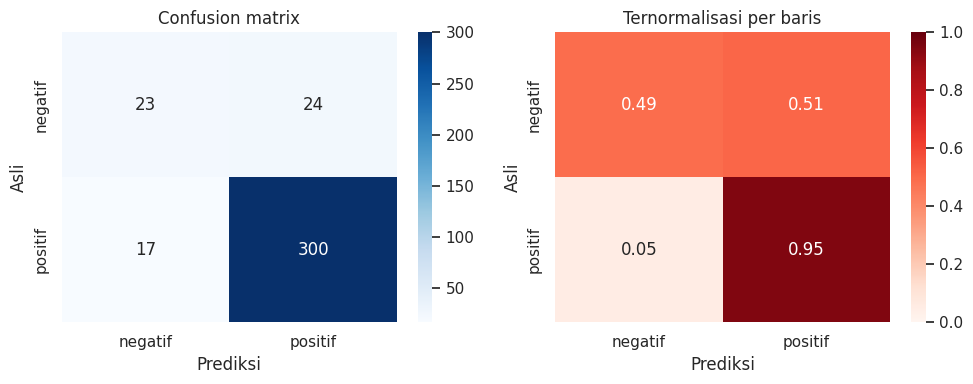

Error rate menurut panjang review:


,jumlah,error_rate
raw_words,,
"(13.999, 26.0]",118,0.093
"(26.0, 29.0]",80,0.050
"(29.0, 35.0]",82,0.134
"(35.0, 88.0]",84,0.179


Kesalahan dengan keyakinan tertinggi (kemungkinan label noise atau sarkasme):


,review,label_name,prediksi,keyakinan
356,"suncreen kecintaan dari dulu sampai sekarang belum pernah berpaling. tekstur watery lebih mudah diratakan dan meresap diwajah, tidak whitecast dan lembabin. super love!",negatif,positif,0.928
64,sejauh ini cocok dipakai untuk muka ku.. tidak membuat terlalu berminyak dan tidak meninggalkan bekas warna putih pada muka.. dan juga melembabkan mukaku,negatif,positif,0.905
2,"untuk orang yang mageran kayak aku maunya serba simple ini jadi opsi yang better sih, tapi sayang pemakaian di aku sedikit nimbulin efek perih dan agak gatal. aku juga kurang suka sama semprotannya yang kurang menyeb...",positif,negatif,0.905
105,"sunscreen murah meriah, enggak terlalu berat tapi cukup lengket, little. acne prone friendly kalo menurut ku, karena aman aman saja dipakai sama cowok ku yang acne prone",negatif,positif,0.827
184,lumayan enak.dia gampang menyerap dan enggak bikin lengket wajahku.wanginya pun tidak mengganggu.saat foto juga dia enggak bikin whitecast..cuma untuk harga segitu masih banyak merk lain yang serupa dalam performa nya,negatif,positif,0.825
75,"sunscreen ringan banget berasa enggak pakai apa apa, untuk kulit kering juga ini oke banget, untuk harga memang cukup mahal tapi kemarin dapat diskon jadi gapapa",negatif,positif,0.811
221,"beli ini pas diskon jadi 1nya cuman 100an include ongkir. teksturenya cair, no whitecast, enggak berminyak. nyerepnya cepet. oke banget deh a senang. wil absolutely repurchase sih kalo diskon. kalo enggak diskon i th...",negatif,positif,0.787
242,"love this product sok much, itu doesn't leave any white cast, itu doesn't burn on my sensitive eczema prone skin, love the cloud like texture, i think i've finished 5 of these? and wil purchase more ini the future. t...",negatif,positif,0.770


In [19]:
best_name = summary.drop_duplicates("model").sort_values("val_macro_f1", ascending=False).iloc[0]["model"]
thr = tune_threshold(y_val, preds[best_name]["val"])
p_neg = preds[best_name]["test"]
pred = np.where(p_neg >= thr, 0, 1)
print(f"Model terbaik (val): {best_name} | threshold={thr:.2f}\n")
print(classification_report(y_test, pred, target_names=LABELS, digits=3, zero_division=0))

cm = confusion_matrix(y_test, pred, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1,
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[0].set_title("Confusion matrix"); axes[1].set_title("Ternormalisasi per baris")
for ax in axes:
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Asli")
plt.tight_layout(); plt.show()

err = test_df[["review", "label_name", "raw_words"]].copy()
err["prediksi"] = pd.Series(pred).map(dict(enumerate(LABELS))).values
err["p_negatif"] = p_neg
err["benar"] = err["label_name"] == err["prediksi"]

print("Error rate menurut panjang review:")
display(err.groupby(pd.qcut(err["raw_words"], 4, duplicates="drop"))["benar"].agg(jumlah="size", error_rate=lambda s: 1 - s.mean()).round(3))

wrong = err[~err["benar"]].copy()
wrong["keyakinan"] = np.where(wrong["prediksi"] == "negatif", wrong["p_negatif"], 1 - wrong["p_negatif"])
print("Kesalahan dengan keyakinan tertinggi (kemungkinan label noise atau sarkasme):")
display(wrong.sort_values("keyakinan", ascending=False).head(8)[["review", "label_name", "prediksi", "keyakinan"]].round(3))